In [1]:
import pandas as pd
import torch
import numpy as np
import random

In [2]:
import pandas as pd
import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler

In [3]:
train_data = pd.read_csv("../data/rck_growth_train.csv")
test_data = pd.read_csv("../data/rck_growth_test.csv")

In [5]:
grid_size = 100


params_cols = ['alpha', 'delta', 'rho', 'theta', 'n', 'g', 'k0_initial', 'c0_initial']
t_grid_cols = [f't_grid_{i}' for i in range(grid_size)]
k_cols = [f'k_t{i}' for i in range(grid_size)]
c_cols = [f'c_t{i}' for i in range(grid_size)]


scaler_params = StandardScaler().fit(train_data[params_cols].values)
scaler_k = StandardScaler().fit(train_data[k_cols].values)
scaler_c = StandardScaler().fit(train_data[c_cols].values)

def prepare_deeponet_tensors(df, scaler_p, scaler_k_obj, scaler_c_obj):
    num_samples = len(df)
    
    # Extract and scale
    params_scaled = scaler_p.transform(df[params_cols].values)
    t_grid = df[t_grid_cols].values
    k_traj_scaled = scaler_k_obj.transform(df[k_cols].values)
    c_traj_scaled = scaler_c_obj.transform(df[c_cols].values)
    
    # BRANCH INPUT

    X_branch = torch.tensor(params_scaled, dtype=torch.float32).unsqueeze(1) # (N, 1, 8)
    
    # TRUNK INPUT
    # (N, 100) -> (N * 100, 1)
    X_trunk = torch.tensor(t_grid, dtype=torch.float32).reshape(-1, 1)
    
    # Y
    k_flat = k_traj_scaled.reshape(-1, 1)
    c_flat = c_traj_scaled.reshape(-1, 1)
    Y = torch.tensor(np.hstack([k_flat, c_flat]), dtype=torch.float32)
    

    X_branch_expanded = X_branch.repeat_interleave(grid_size, dim=0) # (N * 100, 1, 8)
    
    return X_branch_expanded, X_trunk, Y

X_branch_train, X_trunk_train, Y_train = prepare_deeponet_tensors(train_data, scaler_params, scaler_k, scaler_c)
X_branch_test, X_trunk_test, Y_test = prepare_deeponet_tensors(test_data, scaler_params, scaler_k, scaler_c)

print(f"X_branch: {X_branch_train.shape}")  # Expected: [N_train * 100, 1, 8]
print(f"X_trunk:  {X_trunk_train.shape}")   # Expected: [N_train * 100, 1]
print(f"Y (Target):{Y_train.shape}")         # Expected: [N_train * 100, 2]

# 4. Create DeepONet DataLoaders
train_dataset = TensorDataset(X_branch_train, X_trunk_train, Y_train)
test_dataset = TensorDataset(X_branch_test, X_trunk_test, Y_test)

# Using a larger batch size because the dataset size multiplied by 100
train_loader = DataLoader(train_dataset, batch_size=2048, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=2048, shuffle=False)

X_branch: torch.Size([160000, 1, 8])
X_trunk:  torch.Size([160000, 1])
Y (Target):torch.Size([160000, 2])


In [6]:
import random
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

class DynamicConvDeepONet(nn.Module):
    def __init__(self, p_length=8, num_modes=32, branch_channels=16, trunk_hidden=64):
        super().__init__()
        self.num_modes = num_modes
        
        # Branch architecture with variable filter capacity
        self.branch = nn.Sequential(
            nn.Conv1d(in_channels=1, out_channels=branch_channels, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv1d(in_channels=branch_channels, out_channels=branch_channels * 2, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(branch_channels * 2 * p_length, num_modes * 2)
        )
        
        # Trunk architecture with variable linear capacity
        self.trunk = nn.Sequential(
            nn.Linear(1, trunk_hidden),
            nn.ReLU(),
            nn.Linear(trunk_hidden, trunk_hidden),
            nn.ReLU(),
            nn.Linear(trunk_hidden, num_modes * 2)
        )

    def forward(self, x_branch, x_trunk):
        b_out = self.branch(x_branch) 
        t_out = self.trunk(x_trunk)   
        
        b_k, b_c = torch.split(b_out, self.num_modes, dim=-1)
        t_k, t_c = torch.split(t_out, self.num_modes, dim=-1)
        
        out_k = torch.sum(b_k * t_k, dim=-1, keepdim=True)
        out_c = torch.sum(b_c * t_c, dim=-1, keepdim=True)
        return torch.cat([out_k, out_c], dim=-1)


NUM_TRIALS = 10      
TRIAL_EPOCHS = 5      
FINAL_EPOCHS = 100    

hyperparameter_space = {
    'num_modes': [16, 32, 64],
    'branch_channels': [8, 16, 24],
    'trunk_hidden': [32, 64, 128],
    'lr': [1e-3, 3e-3],
    'weight_decay': [1e-5, 1e-4]
}

best_val_loss = float('inf')
best_hparams = None

print(f"---  DeepONet Random Search ({NUM_TRIALS} Trials) ---")

for trial in range(NUM_TRIALS):
    hparams = {key: random.choice(values) for key, values in hyperparameter_space.items()}
    print(f"\n[Trial {trial+1}/{NUM_TRIALS}] Evaluation Stack: {hparams}")
    
    #  current trial candidate
    model = DynamicConvDeepONet(
        p_length=8,
        num_modes=hparams['num_modes'],
        branch_channels=hparams['branch_channels'],
        trunk_hidden=hparams['trunk_hidden']
    )
    
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=hparams['lr'], weight_decay=hparams['weight_decay'])
    
    model.train()
    for epoch in range(TRIAL_EPOCHS):
        for x_b, x_t, y in train_loader:
            optimizer.zero_grad()
            pred = model(x_b, x_t)
            loss = criterion(pred, y)
            loss.backward()
            optimizer.step()
            
    # Evaluation Pass
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for x_b, x_t, y in test_loader:
            pred = model(x_b, x_t)
            loss = criterion(pred, y)
            val_loss += loss.item() * x_b.size(0)
    val_loss /= len(test_loader.dataset)
    
    print(f"Trial {trial+1}  Val Loss (MSE): {val_loss:.6f}")
    
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_hparams = hparams

print(f"Best Configuration: {best_hparams}")


print(f"\n---  Final Model for {FINAL_EPOCHS} Epochs ---")

final_deeponet = DynamicConvDeepONet(
    p_length=8,
    num_modes=best_hparams['num_modes'],
    branch_channels=best_hparams['branch_channels'],
    trunk_hidden=best_hparams['trunk_hidden']
)

criterion = nn.MSELoss()
optimizer = optim.Adam(final_deeponet.parameters(), lr=best_hparams['lr'], weight_decay=best_hparams['weight_decay'])
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=6, factor=0.5)

train_losses = []
val_losses = []

for epoch in range(FINAL_EPOCHS):
    final_deeponet.train()
    train_loss = 0.0
    for x_b, x_t, y in train_loader:
        optimizer.zero_grad()
        pred = final_deeponet(x_b, x_t)
        loss = criterion(pred, y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * x_b.size(0)
    train_loss /= len(train_loader.dataset)
    train_losses.append(train_loss)
    
    final_deeponet.eval()
    val_loss = 0.0
    with torch.no_grad():
        for x_b, x_t, y in test_loader:
            pred = final_deeponet(x_b, x_t)
            loss = criterion(pred, y)
            val_loss += loss.item() * x_b.size(0)
    val_loss /= len(test_loader.dataset)
    val_losses.append(val_loss)
    
    scheduler.step(val_loss)
    
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1}/{FINAL_EPOCHS}] -> Running Train Loss: {train_loss:.6f} | Val Loss: {val_loss:.6f}")


---  DeepONet Random Search (10 Trials) ---

[Trial 1/10] Evaluation Stack: {'num_modes': 32, 'branch_channels': 16, 'trunk_hidden': 32, 'lr': 0.003, 'weight_decay': 1e-05}
Trial 1  Val Loss (MSE): 0.009218

[Trial 2/10] Evaluation Stack: {'num_modes': 16, 'branch_channels': 24, 'trunk_hidden': 128, 'lr': 0.001, 'weight_decay': 1e-05}
Trial 2  Val Loss (MSE): 0.010634

[Trial 3/10] Evaluation Stack: {'num_modes': 16, 'branch_channels': 8, 'trunk_hidden': 32, 'lr': 0.003, 'weight_decay': 0.0001}
Trial 3  Val Loss (MSE): 0.013824

[Trial 4/10] Evaluation Stack: {'num_modes': 16, 'branch_channels': 24, 'trunk_hidden': 64, 'lr': 0.003, 'weight_decay': 1e-05}
Trial 4  Val Loss (MSE): 0.010939

[Trial 5/10] Evaluation Stack: {'num_modes': 16, 'branch_channels': 8, 'trunk_hidden': 128, 'lr': 0.001, 'weight_decay': 0.0001}
Trial 5  Val Loss (MSE): 0.014751

[Trial 6/10] Evaluation Stack: {'num_modes': 16, 'branch_channels': 24, 'trunk_hidden': 64, 'lr': 0.003, 'weight_decay': 1e-05}
Trial 6  V

In [7]:

final_deeponet.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for x_b, x_t, y in test_loader:
        pred = final_deeponet(x_b, x_t) # Shape: [Batch, 2]
        all_preds.append(pred.numpy())
        all_targets.append(y.numpy())

all_preds = np.concatenate(all_preds, axis=0)     # Shape: (N_test * 100, 2)
all_targets = np.concatenate(all_targets, axis=0) # Shape: (N_test * 100, 2)

# Reshape back from single data streams to original grid sequences: (N_test, 100, 2)
num_test_simulations = len(test_data)
all_preds = all_preds.reshape(num_test_simulations, grid_size, 2)
all_targets = all_targets.reshape(num_test_simulations, grid_size, 2)

# Unscale channels
preds_k = scaler_k.inverse_transform(all_preds[:, :, 0])
preds_c = scaler_c.inverse_transform(all_preds[:, :, 1])
targets_k = scaler_k.inverse_transform(all_targets[:, :, 0])
targets_c = scaler_c.inverse_transform(all_targets[:, :, 1])

# Extract time coordinates
time_axis = test_data[[f't_grid_{i}' for i in range(grid_size)]].iloc[0].values

# Compute Absolute Errors
abs_error_k = np.abs(targets_k - preds_k)
abs_error_c = np.abs(targets_c - preds_c)


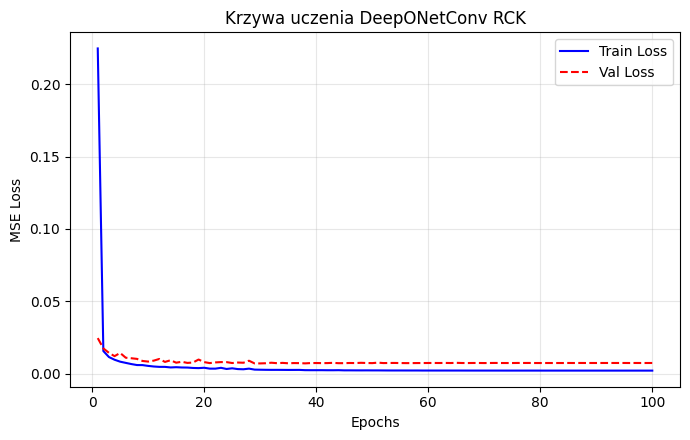

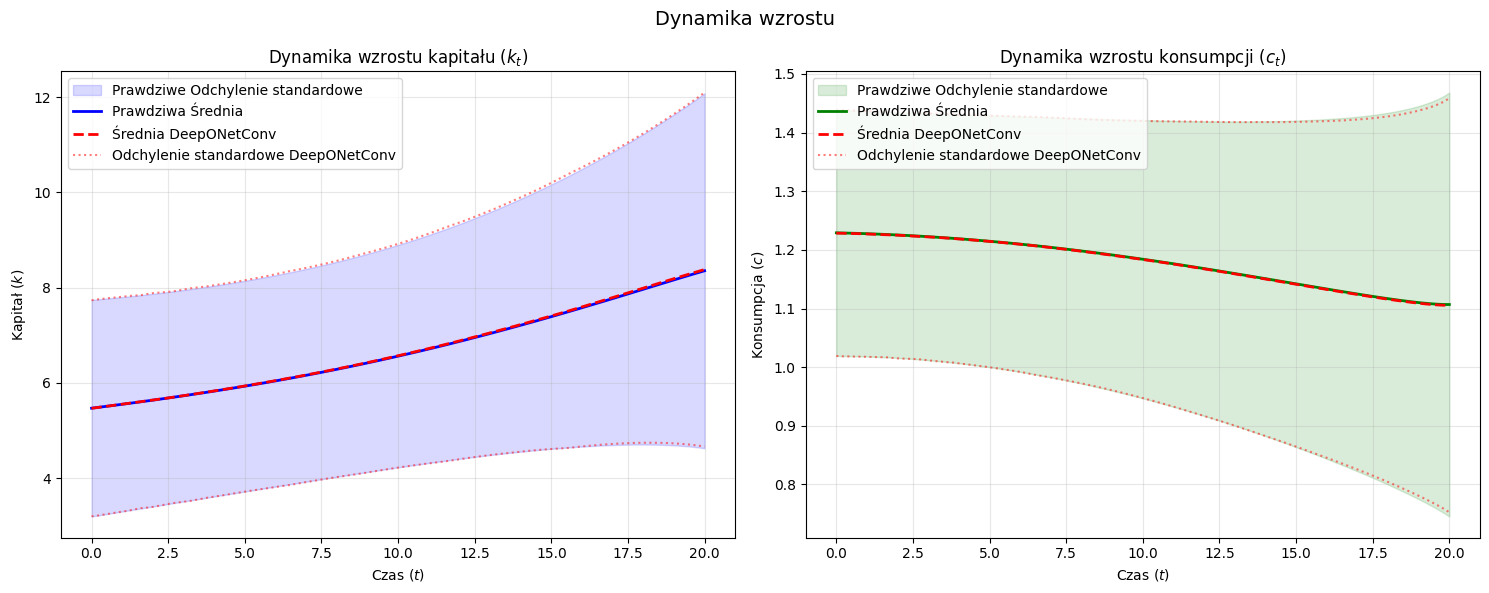

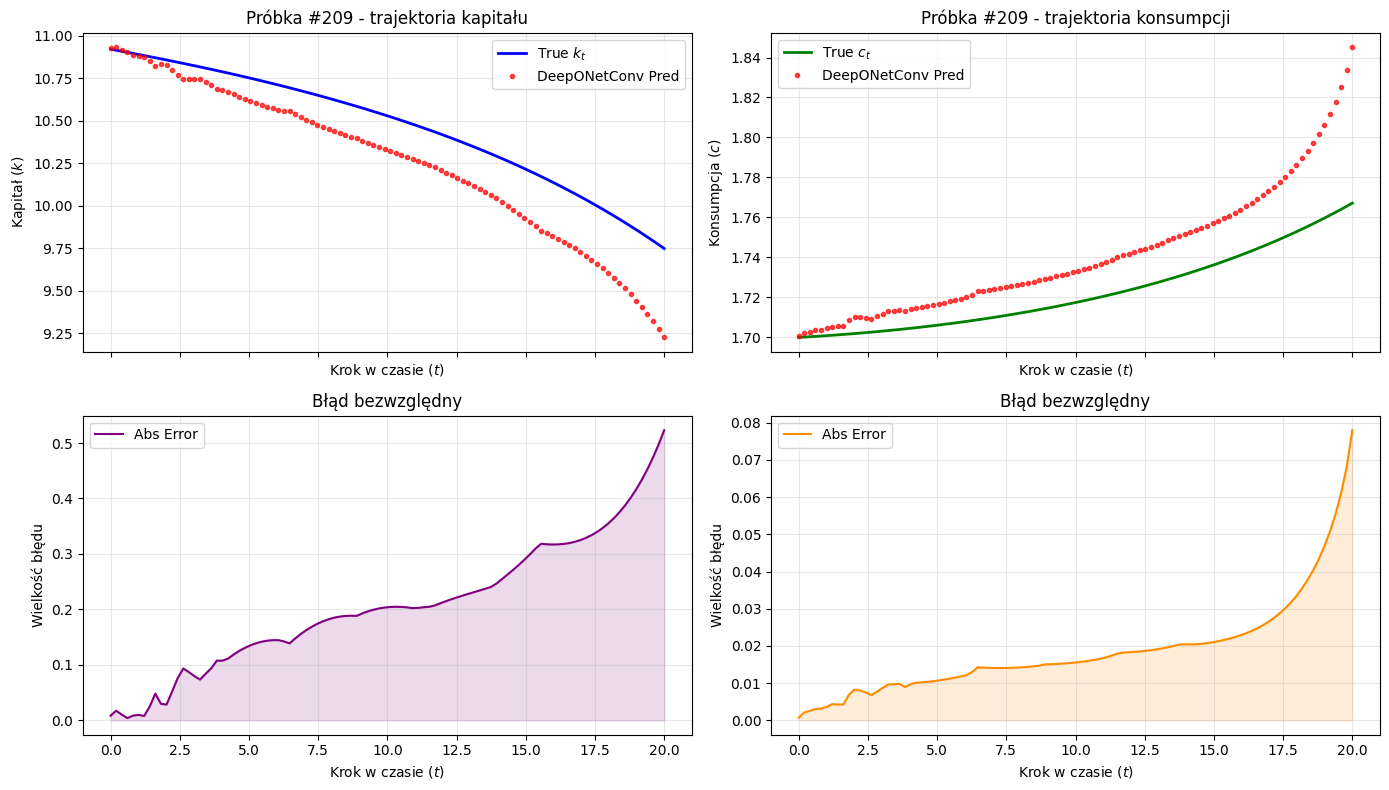

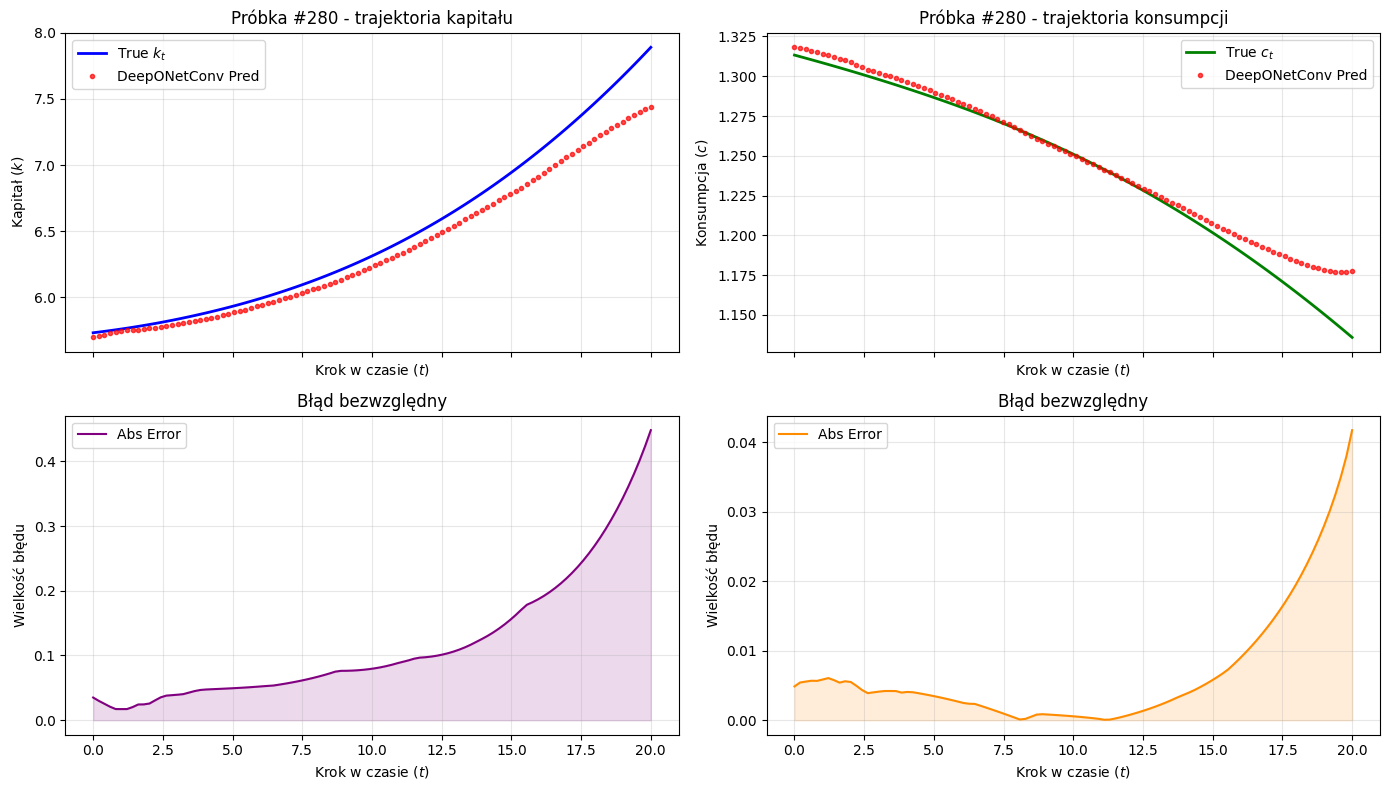

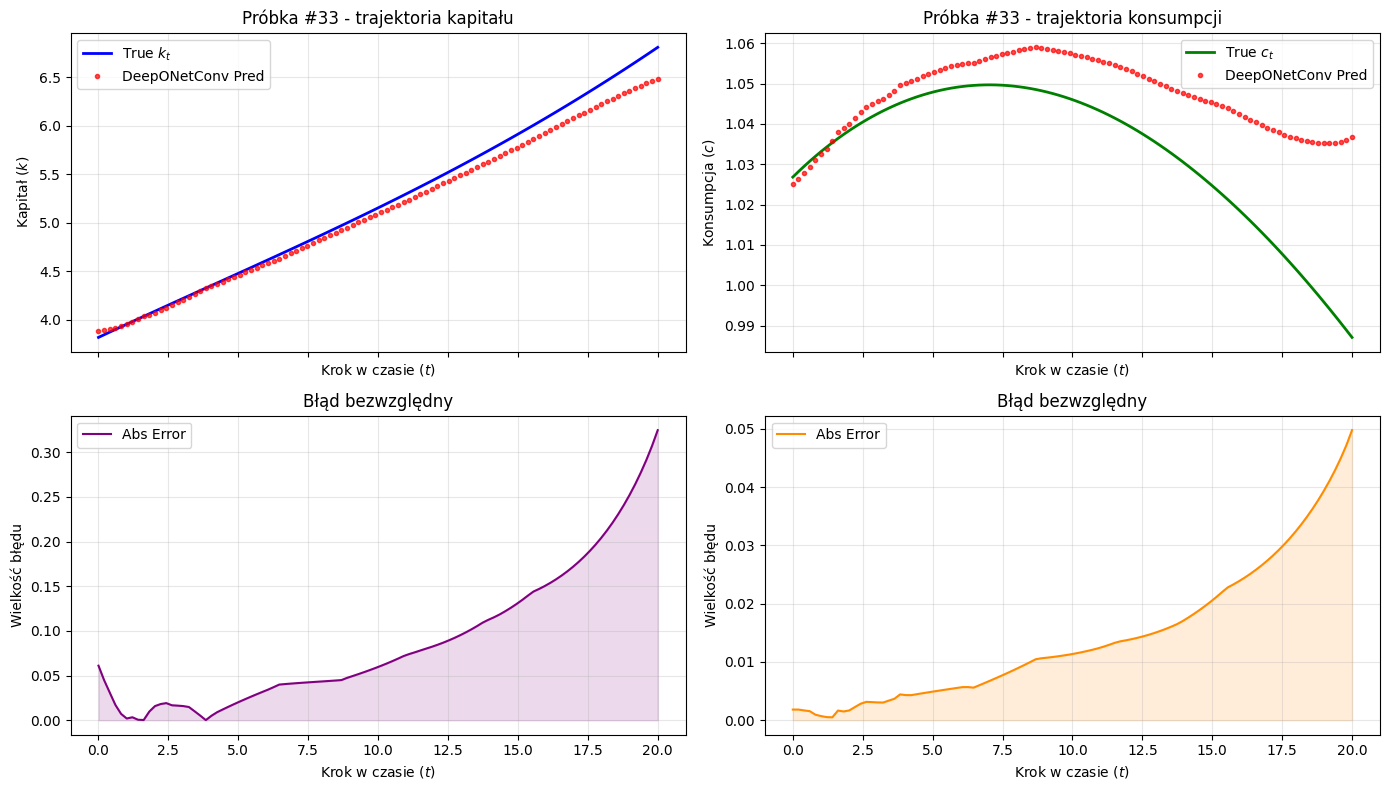

In [10]:
import os
import matplotlib.pyplot as plt

output_dir = "DEEpONetConv_rck_plots"
os.makedirs(output_dir, exist_ok=True)

plt.figure(figsize=(7, 4.5))
plt.plot(range(1, FINAL_EPOCHS + 1), train_losses, label='Train Loss', color='blue', linewidth=1.5)
plt.plot(range(1, FINAL_EPOCHS + 1), val_losses, label='Val Loss', color='red', linestyle='--', linewidth=1.5)
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.title('Krzywa uczenia DeepONetConv RCK')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save Plot 1
plot1_path = os.path.join(output_dir, "loss_history_DeepONetConv_RCK.png")
plt.savefig(plot1_path, dpi=300, bbox_inches='tight')
plt.show()


mean_target_k, mean_pred_k = targets_k.mean(axis=0), preds_k.mean(axis=0)
mean_target_c, mean_pred_c = targets_c.mean(axis=0), preds_c.mean(axis=0)
std_target_k, std_pred_k   = targets_k.std(axis=0), preds_k.std(axis=0)
std_target_c, std_pred_c   = targets_c.std(axis=0), preds_c.std(axis=0)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# --- Left Subplot: Capital ---
axes[0].fill_between(time_axis, mean_target_k - std_target_k, mean_target_k + std_target_k, 
                     color='blue', alpha=0.15, label='Prawdziwe Odchylenie standardowe')
axes[0].plot(time_axis, mean_target_k, color='blue', linewidth=2, label='Prawdziwa Średnia')
axes[0].plot(time_axis, mean_pred_k, color='red', linestyle='--', linewidth=2, label='Średnia DeepONetConv')
axes[0].plot(time_axis, mean_pred_k + std_pred_k, color='red', linestyle=':', alpha=0.5)
axes[0].plot(time_axis, mean_pred_k - std_pred_k, color='red', linestyle=':', alpha=0.5, label='Odchylenie standardowe DeepONetConv')
axes[0].set_title('Dynamika wzrostu kapitału ($k_t$)')
axes[0].set_xlabel('Czas ($t$)')
axes[0].set_ylabel('Kapitał ($k$)')
axes[0].legend(loc='upper left')
axes[0].grid(True, alpha=0.3)

# --- Right Subplot: Consumption ---
axes[1].fill_between(time_axis, mean_target_c - std_target_c, mean_target_c + std_target_c, 
                     color='green', alpha=0.15, label='Prawdziwe Odchylenie standardowe')
axes[1].plot(time_axis, mean_target_c, color='green', linewidth=2, label='Prawdziwa Średnia')
axes[1].plot(time_axis, mean_pred_c, color='red', linestyle='--', linewidth=2, label='Średnia DeepONetConv')
axes[1].plot(time_axis, mean_pred_c + std_pred_c, color='red', linestyle=':', alpha=0.5)
axes[1].plot(time_axis, mean_pred_c - std_pred_c, color='red', linestyle=':', alpha=0.5, label='Odchylenie standardowe DeepONetConv')
axes[1].set_title('Dynamika wzrostu konsumpcji ($c_t$)')
axes[1].set_xlabel('Czas ($t$)')
axes[1].set_ylabel('Konsumpcja ($c$)')
axes[1].legend(loc='upper left')
axes[1].grid(True, alpha=0.3)

plt.suptitle('Dynamika wzrostu', fontsize=14, y=0.98)
plt.tight_layout()

# Save Plot 2
plot2_path = os.path.join(output_dir, "RCK_DeepONetConv_growth_dynamics.png")
plt.savefig(plot2_path, dpi=300, bbox_inches='tight')
plt.show()



np.random.seed(42) 
random_indices = np.random.choice(len(all_preds), size=3, replace=False)

for sample_idx in random_indices:
    fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
    

    # Top Left: Profiles
    axes[0, 0].plot(time_axis, targets_k[sample_idx], 'b-', linewidth=2, label='True $k_t$')
    axes[0, 0].plot(time_axis, preds_k[sample_idx], 'ro', markersize=3, alpha=0.7, label='DeepONetConv Pred')
    axes[0, 0].set_title(f'Próbka #{sample_idx} - trajektoria kapitału')
    axes[0, 0].set_ylabel('Kapitał ($k$)')
    axes[0, 0].set_xlabel('Krok w czasie ($t$)')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)
    
    # Bottom Left: Absolute Error
    axes[1, 0].fill_between(time_axis, abs_error_k[sample_idx], color='purple', alpha=0.15)
    axes[1, 0].plot(time_axis, abs_error_k[sample_idx], color='purple', linewidth=1.5, label='Abs Error')
    axes[1, 0].set_title('Błąd bezwzględny')
    axes[1, 0].set_xlabel('Krok w czasie ($t$)')
    axes[1, 0].set_ylabel('Wielkość błędu')
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)
    

    # Top Right: Profiles
    axes[0, 1].plot(time_axis, targets_c[sample_idx], 'g-', linewidth=2, label='True $c_t$')
    axes[0, 1].plot(time_axis, preds_c[sample_idx], 'ro', markersize=3, alpha=0.7, label='DeepONetConv Pred')
    axes[0, 1].set_title(f'Próbka #{sample_idx} - trajektoria konsumpcji')
    axes[0, 1].set_ylabel('Konsumpcja ($c$)')
    axes[0, 1].set_xlabel('Krok w czasie ($t$)')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)
    
    # Bottom Right: Absolute Error
    axes[1, 1].fill_between(time_axis, abs_error_c[sample_idx], color='darkorange', alpha=0.15)
    axes[1, 1].plot(time_axis, abs_error_c[sample_idx], color='darkorange', linewidth=1.5, label='Abs Error')
    axes[1, 1].set_title('Błąd bezwzględny')
    axes[1, 1].set_xlabel('Krok w czasie ($t$)')
    axes[1, 1].set_ylabel('Wielkość błędu')
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    # Save a separate plot file for each distinct sample checked
    plot3_path = os.path.join(output_dir, f"3_sample_{sample_idx}_analysis_DeepONetConv_RCK.png")
    plt.savefig(plot3_path, dpi=300, bbox_inches='tight')
    plt.show()
